In [3]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 


In [4]:
df = pd.read_csv(
    "../data/processed/online_retail_clean.csv",
    parse_dates=["InvoiceDate"]
)

In [5]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [6]:
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

In [8]:
total_revenue = df["TotalPrice"].sum()

total_revenue

np.float64(8887208.894000001)

In [9]:
revenue_by_country = (
    df.groupby("Country")["TotalPrice"]
      .sum()
      .sort_values(ascending=False)
)

revenue_by_country.head(10)

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: TotalPrice, dtype: float64

In [10]:
uk_revenue = revenue_by_country["United Kingdom"]

uk_percentage = (uk_revenue / total_revenue) * 100

uk_percentage

np.float64(81.972019909629)

In [11]:
top_10_countries = revenue_by_country.head(10)

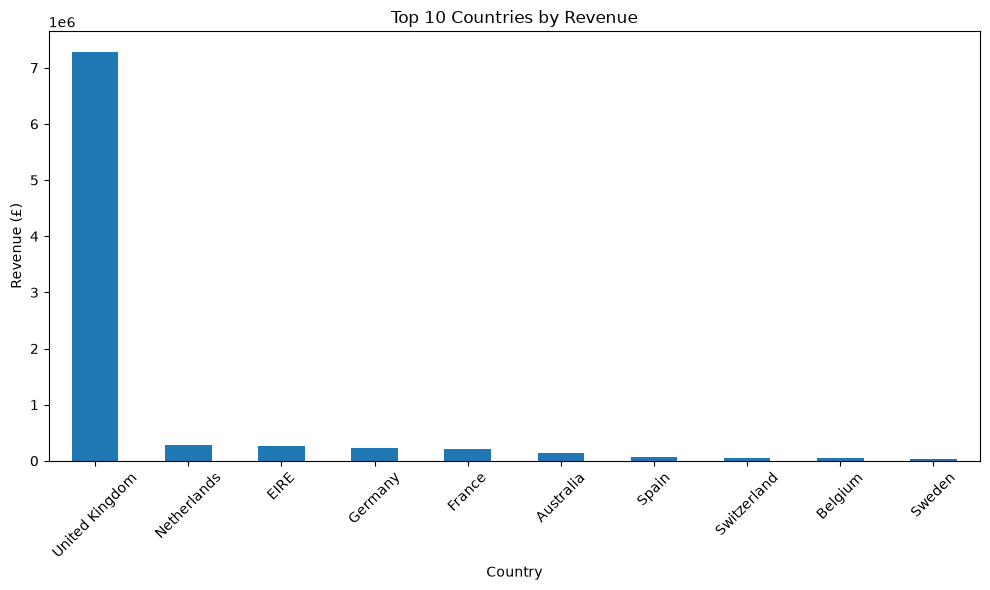

In [12]:
plt.figure(figsize=(10, 6))

top_10_countries.plot(kind="bar")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [13]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [20]:
df = pd.read_csv(
    "../data/processed/online_retail_clean.csv",
    parse_dates=["InvoiceDate"]
)


In [21]:
type(df)

pandas.DataFrame

In [22]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalPrice'],
      dtype='str')

In [24]:
df["Month"] = df["InvoiceDate"].dt.to_period("M")

In [25]:
df["Month"].head()

0    2010-12
1    2010-12
2    2010-12
3    2010-12
4    2010-12
Name: Month, dtype: period[M]

In [29]:

monthly_revenue = df.groupby("Month")["TotalPrice"].sum()

In [30]:
monthly_revenue.head()

Month
2010-12    570422.730
2011-01    568101.310
2011-02    446084.920
2011-03    594081.760
2011-04    468374.331
Freq: M, Name: TotalPrice, dtype: float64

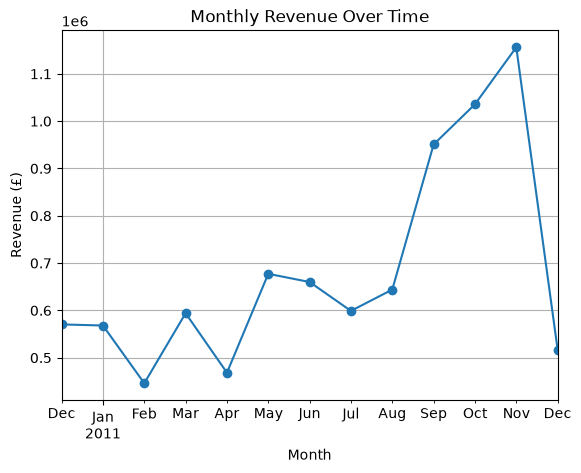

In [33]:
monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Over Time")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.grid()

plt.show()


In [34]:
df["InvoiceDate"].min()

Timestamp('2010-12-01 08:26:00')

In [35]:
df["InvoiceDate"].max()

Timestamp('2011-12-09 12:50:00')

In [36]:
monthly_revenue.idxmax()

Period('2011-11', 'M')

In [37]:
monthly_revenue.max()


np.float64(1156205.61)

In [40]:
top_products = (df.groupby("Description")["Quantity"].sum().sort_values(ascending= False))

In [42]:
top_products.head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30919
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64

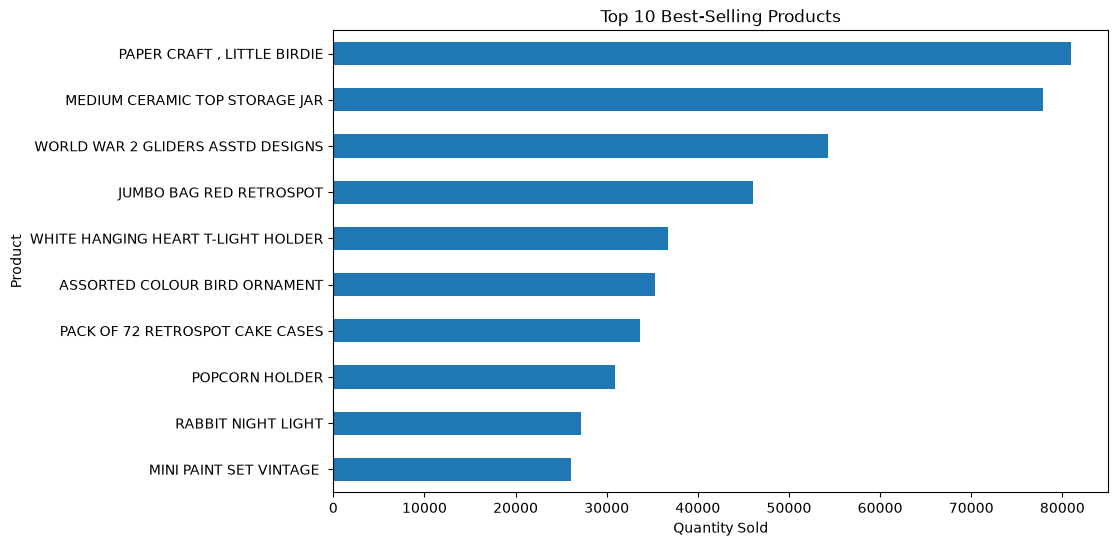

In [48]:
top_10_products = top_products.head(10)

top_10_products.plot(kind="barh", figsize=(10, 6))

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.gca().invert_yaxis()
plt.show()

In [49]:
top_client = (
    df.groupby("CustomerID")["TotalPrice"]
      .sum()
      .sort_values(ascending=False)
)

top_client.head(10)

CustomerID
14646    280206.02
18102    259657.30
17450    194390.79
16446    168472.50
14911    143711.17
12415    124914.53
14156    117210.08
17511     91062.38
16029     80850.84
12346     77183.60
Name: TotalPrice, dtype: float64

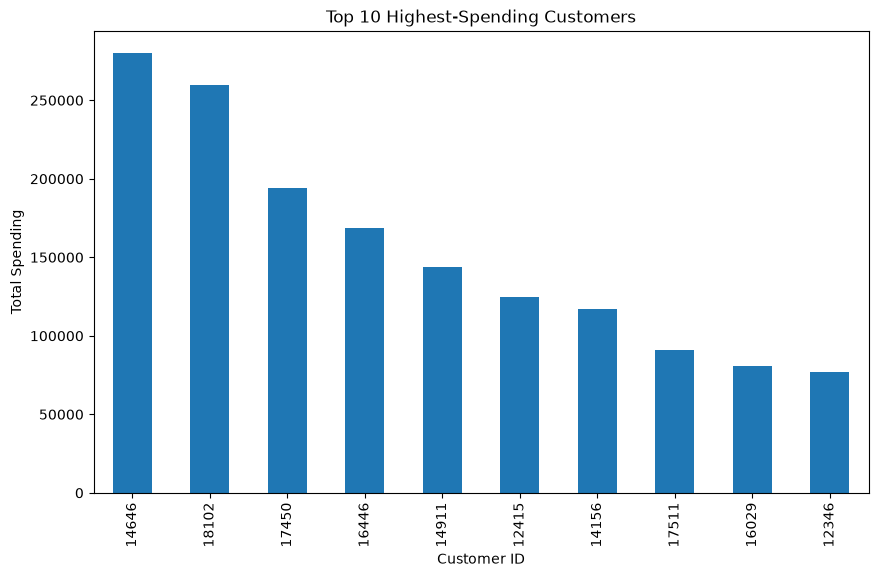

In [54]:
top_10_client = top_client.head(10)

top_client.plot(kind= "bar", figsize=(10, 6))

plt.title("Top 10 Highest-Spending Customers")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")
plt.show()

In [58]:
df ["CustomerID"].nunique()


4338

In [57]:
df["InvoiceNo"].nunique()

18532

In [60]:
df["InvoiceNo"].nunique()

18532

In [61]:
df["InvoiceNo"].head(20)

0     536365
1     536365
2     536365
3     536365
4     536365
5     536365
6     536365
7     536366
8     536366
9     536367
10    536367
11    536367
12    536367
13    536367
14    536367
15    536367
16    536367
17    536367
18    536367
19    536367
Name: InvoiceNo, dtype: int64

In [62]:
df.shape

(392692, 10)

In [63]:
df["InvoiceNo"].nunique()

18532

In [64]:
df["InvoiceNo"].nunique() / df["CustomerID"].nunique()



4.272014753342554

In [65]:
orders_per_customer = (
    df.groupby("CustomerID")["InvoiceNo"]
      .nunique()
)

In [66]:
orders_per_customer.head(10)

CustomerID
12346    1
12347    7
12348    4
12349    1
12350    1
12352    8
12353    1
12354    1
12355    1
12356    3
Name: InvoiceNo, dtype: int64

In [67]:
orders_per_customer.describe()

count    4338.000000
mean        4.272015
std         7.697998
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       209.000000
Name: InvoiceNo, dtype: float64

In [68]:
orders_per_customer.idxmax()

np.int64(12748)

In [69]:
df[df["CustomerID"] == 12748]["TotalPrice"].sum()

np.float64(33053.19)

In [70]:
orders_per_customer.loc[14646]

np.int64(73)